# Laboratorium 2 — Rekurencyjne odwracanie macierzy, faktoryzacja LU oraz mnożenie metodą Ladermana

In [1]:
import os
import sys
import time
import math
import subprocess
import numpy as np
import matplotlib.pyplot as plt

if os.path.exists(".pydeps"):
    sys.path.insert(0, os.path.abspath(".pydeps"))

if not any(f.startswith("matrix_algos_cy") and f.endswith(".so") for f in os.listdir(".")):
    subprocess.check_call([sys.executable, "setup.py", "build_ext", "--inplace"])

import matrix_algos_cy as cy

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
os.makedirs("typst/imgs", exist_ok=True)

In [2]:
def generate_random_matrix(size: int, low: float = 0.00000001, high: float = 1.0, seed: int = None) -> np.ndarray:
    if seed is not None:
        np.random.seed(seed)
    return np.ascontiguousarray(low + (high - low) * np.random.rand(size, size), dtype=np.float64)


def next_pow2(n: int) -> int:
    p = 1
    while p < n:
        p <<= 1
    return p


def next_pow3(n: int) -> int:
    p = 1
    while p < n:
        p *= 3
    return p

## 1. Rekurencyjne mnożenie macierzy metodą Ladermana

In [3]:
test_sizes = [1, 2, 3, 4, 5, 9, 10, 15, 27, 50, 81, 100]
print(
    f"{'n':>4} | {'Metoda':<10} | {'allclose':<8} | {'max_err':>10} | {'Mnożenia':>12} | {'Dod./Odejm.':>14} | {'FLOPs łącznie':>14}")
print("-" * 88)

for n in test_sizes:
    A = generate_random_matrix(n, seed=100 + n)
    B = generate_random_matrix(n, seed=200 + n)
    ref = A @ B
    for name, fn in [("Binet", cy.binet_mul), ("Strassen", cy.strassen_mul), ("Laderman", cy.laderman_mul)]:
        got, m_ops, as_ops, flops = fn(A, B)
        err = np.max(np.abs(ref - got))
        ok = np.allclose(ref, got, atol=1e-6, rtol=1e-6)
        print(f"{n:4d} | {name:<10} | {str(ok):<8} | {err:10.2e} | {m_ops:12d} | {as_ops:14d} | {flops:14d}")

   n | Metoda     | allclose |    max_err |     Mnożenia |    Dod./Odejm. |  FLOPs łącznie
----------------------------------------------------------------------------------------
   1 | Binet      | True     |   0.00e+00 |            1 |              0 |              1
   1 | Strassen   | True     |   0.00e+00 |            1 |              0 |              1
   1 | Laderman   | True     |   0.00e+00 |            1 |              0 |              1
   2 | Binet      | True     |   1.11e-16 |            8 |              4 |             12
   2 | Strassen   | True     |   2.22e-16 |            7 |             18 |             25
   2 | Laderman   | True     |   0.00e+00 |           23 |             98 |            121
   3 | Binet      | True     |   0.00e+00 |           64 |             48 |            112
   3 | Strassen   | True     |   3.33e-16 |           49 |            198 |            247
   3 | Laderman   | True     |   2.22e-16 |           23 |             98 |            121
 

## 2. Rekurencyjne odwracanie macierzy (Binet, Strassen, Laderman)

In [4]:
print(
    f"{'n':>4} | {'Metoda Inv':<14} | {'allclose':<8} | {'||A*A^-1 - I||':>14} | {'Mnożenia':>12} | {'Dod./Odejm.':>14} | {'FLOPs łącznie':>14}")
print("-" * 96)

for n in [1, 2, 3, 4, 5, 8, 10, 16, 27, 50, 64, 100]:
    A = generate_random_matrix(n, seed=300 + n)
    for name, fn in [("Inv+Binet", cy.inverse_binet), ("Inv+Strassen", cy.inverse_strassen),
                     ("Inv+Laderman", cy.inverse_laderman)]:
        inv_A, m_ops, as_ops, flops = fn(A)
        ident_err = np.max(np.abs(A @ inv_A - np.eye(n))) if n > 1 else abs(A[0, 0] * inv_A[0, 0] - 1.0)
        ok = np.allclose(A @ inv_A, np.eye(n), atol=1e-4, rtol=1e-4)
        print(f"{n:4d} | {name:<14} | {str(ok):<8} | {ident_err:14.2e} | {m_ops:12d} | {as_ops:14d} | {flops:14d}")

   n | Metoda Inv     | allclose | ||A*A^-1 - I|| |     Mnożenia |    Dod./Odejm. |  FLOPs łącznie
------------------------------------------------------------------------------------------------
   1 | Inv+Binet      | True     |       0.00e+00 |            1 |              0 |              1
   1 | Inv+Strassen   | True     |       0.00e+00 |            1 |              0 |              1
   1 | Inv+Laderman   | True     |       0.00e+00 |            1 |              0 |              1
   2 | Inv+Binet      | True     |       3.33e-16 |            8 |              4 |             12
   2 | Inv+Strassen   | True     |       3.33e-16 |            8 |              4 |             12
   2 | Inv+Laderman   | True     |       3.33e-16 |            8 |              4 |             12
   3 | Inv+Binet      | True     |       2.22e-16 |           57 |             37 |             94
   3 | Inv+Strassen   | True     |       5.64e-16 |           51 |            121 |            172
   3 | Inv+L

## 3. Rekurencyjna faktoryzacja LU (Binet, Strassen, Laderman)

In [5]:
print(
    f"{'n':>4} | {'Metoda LU':<14} | {'allclose':<8} | {'||L*U - A||':>12} | {'Mnożenia':>12} | {'Dod./Odejm.':>14} | {'FLOPs łącznie':>14}")
print("-" * 94)

for n in [1, 2, 3, 4, 5, 8, 10, 16, 27, 50, 64, 100]:
    A = generate_random_matrix(n, seed=500 + n)
    for name, fn in [("LU+Binet", cy.lu_binet), ("LU+Strassen", cy.lu_strassen), ("LU+Laderman", cy.lu_laderman)]:
        L, U, m_ops, as_ops, flops = fn(A)
        lu_err = np.max(np.abs(L @ U - A))
        ok = np.allclose(L @ U, A, atol=1e-5, rtol=1e-5)
        print(f"{n:4d} | {name:<14} | {str(ok):<8} | {lu_err:12.2e} | {m_ops:12d} | {as_ops:14d} | {flops:14d}")

   n | Metoda LU      | allclose |  ||L*U - A|| |     Mnożenia |    Dod./Odejm. |  FLOPs łącznie
----------------------------------------------------------------------------------------------
   1 | LU+Binet       | True     |     0.00e+00 |            0 |              0 |              0
   1 | LU+Strassen    | True     |     0.00e+00 |            0 |              0 |              0
   1 | LU+Laderman    | True     |     0.00e+00 |            0 |              0 |              0
   2 | LU+Binet       | True     |     2.36e-16 |            5 |              1 |              6
   2 | LU+Strassen    | True     |     2.36e-16 |            5 |              1 |              6
   2 | LU+Laderman    | True     |     2.36e-16 |            5 |              1 |              6
   3 | LU+Binet       | True     |     7.77e-16 |           31 |             17 |             48
   3 | LU+Strassen    | True     |     9.99e-16 |           28 |             59 |             87
   3 | LU+Laderman    | True    

## 4. Przykład dla małej macierzy 3x3

In [6]:
A_small = np.array([[2.0, 1.0, 1.0],
                    [4.0, -6.0, 0.0],
                    [-2.0, 7.0, 2.0]], dtype=np.float64)

B_small = np.array([[1.0, 2.0, 0.0],
                    [0.0, 1.0, 1.0],
                    [2.0, 0.0, 1.0]], dtype=np.float64)

C_lad, m_l, as_l, f_l = cy.laderman_mul(A_small, B_small)
print("Mnożenie Ladermana (A * B):")
print(C_lad)
print(
    f"Zgodność z A @ B: {np.allclose(C_lad, A_small @ B_small)} | Mnożenia: {m_l}, Dod./Odejm.: {as_l}, FLOPs: {f_l}\n")

inv_b, m_ib, as_ib, f_ib = cy.inverse_binet(A_small)
inv_s, m_is, as_is, f_is = cy.inverse_strassen(A_small)
inv_l, m_il, as_il, f_il = cy.inverse_laderman(A_small)
print("Macierz odwrotna A^-1:")
print(inv_b)
print(
    f"Zgodność z np.linalg.inv: {np.allclose(inv_b, np.linalg.inv(A_small))} / {np.allclose(inv_s, np.linalg.inv(A_small))} / {np.allclose(inv_l, np.linalg.inv(A_small))}")
print(f"FLOPs odwracania (3x3): Binet={f_ib}, Strassen={f_is}, Laderman={f_il}\n")

L_b, U_b, m_lub, as_lub, f_lub = cy.lu_binet(A_small)
L_s, U_s, m_lus, as_lus, f_lus = cy.lu_strassen(A_small)
det_val, m_det, as_det, f_det = cy.det_lu(A_small, 0)
print("Faktoryzacja LU macierzy A:")
print("L:\n", L_b)
print("U:\n", U_b)
print(
    f"L @ U == A: {np.allclose(L_b @ U_b, A_small)} | det(A): {det_val:.4f} (np.linalg.det: {np.linalg.det(A_small):.4f})")
print(f"FLOPs LU (3x3): Binet={f_lub}, Strassen={f_lus}")

Mnożenie Ladermana (A * B):
[[ 4.  5.  2.]
 [ 4.  2. -6.]
 [ 2.  3.  9.]]
Zgodność z A @ B: True | Mnożenia: 23, Dod./Odejm.: 98, FLOPs: 121

Macierz odwrotna A^-1:
[[ 0.75   -0.3125 -0.375 ]
 [ 0.5    -0.375  -0.25  ]
 [-1.      1.      1.    ]]
Zgodność z np.linalg.inv: True / True / True
FLOPs odwracania (3x3): Binet=94, Strassen=172, Laderman=748

Faktoryzacja LU macierzy A:
L:
 [[ 1.  0.  0.]
 [ 2.  1.  0.]
 [-1. -1.  1.]]
U:
 [[ 2.  1.  1.]
 [ 0. -8. -2.]
 [ 0.  0.  1.]]
L @ U == A: True | det(A): -16.0000 (np.linalg.det: -16.0000)
FLOPs LU (3x3): Binet=48, Strassen=87


## 5. Pomiary do rozmiaru n = 100 oraz n = 1000

In [7]:
sizes = sorted(list(set(
    list(range(1, 130)) +
    list(range(130, 260, 5)) +
    list(range(260, 520, 15)) +
    list(range(520, 1001, 40)) +
    [81, 128, 162, 243, 256, 324, 486, 512, 729, 1000]
)))

results = {
    "mul_binet": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "mul_strassen": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "mul_laderman": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "inv_binet": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "inv_strassen": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "inv_laderman": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "lu_binet": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "lu_strassen": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
    "lu_laderman": {"time": [], "m_ops": [], "as_ops": [], "flops": []},
}

t_start_all = time.perf_counter()
for n in sizes:
    A = generate_random_matrix(n, seed=1000 + n)
    B = generate_random_matrix(n, seed=2000 + n)

    for key, fn in [("mul_binet", cy.binet_mul), ("mul_strassen", cy.strassen_mul), ("mul_laderman", cy.laderman_mul)]:
        t0 = time.perf_counter()
        _, m_ops, as_ops, flops = fn(A, B)
        dt = time.perf_counter() - t0
        results[key]["time"].append(dt)
        results[key]["m_ops"].append(m_ops)
        results[key]["as_ops"].append(as_ops)
        results[key]["flops"].append(flops)

    for key, fn in [("inv_binet", cy.inverse_binet), ("inv_strassen", cy.inverse_strassen),
                    ("inv_laderman", cy.inverse_laderman)]:
        t0 = time.perf_counter()
        _, m_ops, as_ops, flops = fn(A)
        dt = time.perf_counter() - t0
        results[key]["time"].append(dt)
        results[key]["m_ops"].append(m_ops)
        results[key]["as_ops"].append(as_ops)
        results[key]["flops"].append(flops)

    for key, fn in [("lu_binet", cy.lu_binet), ("lu_strassen", cy.lu_strassen), ("lu_laderman", cy.lu_laderman)]:
        t0 = time.perf_counter()
        _, _, m_ops, as_ops, flops = fn(A)
        dt = time.perf_counter() - t0
        results[key]["time"].append(dt)
        results[key]["m_ops"].append(m_ops)
        results[key]["as_ops"].append(as_ops)
        results[key]["flops"].append(flops)

sizes_100 = sizes[:100]
print(f"Pomiary dla n do {sizes[-1]} zakończone w {time.perf_counter() - t_start_all:.2f} s.")

Pomiary dla n do 1000 zakończone w 179.84 s.


### Wykresy dla $n_{\max} = 100$

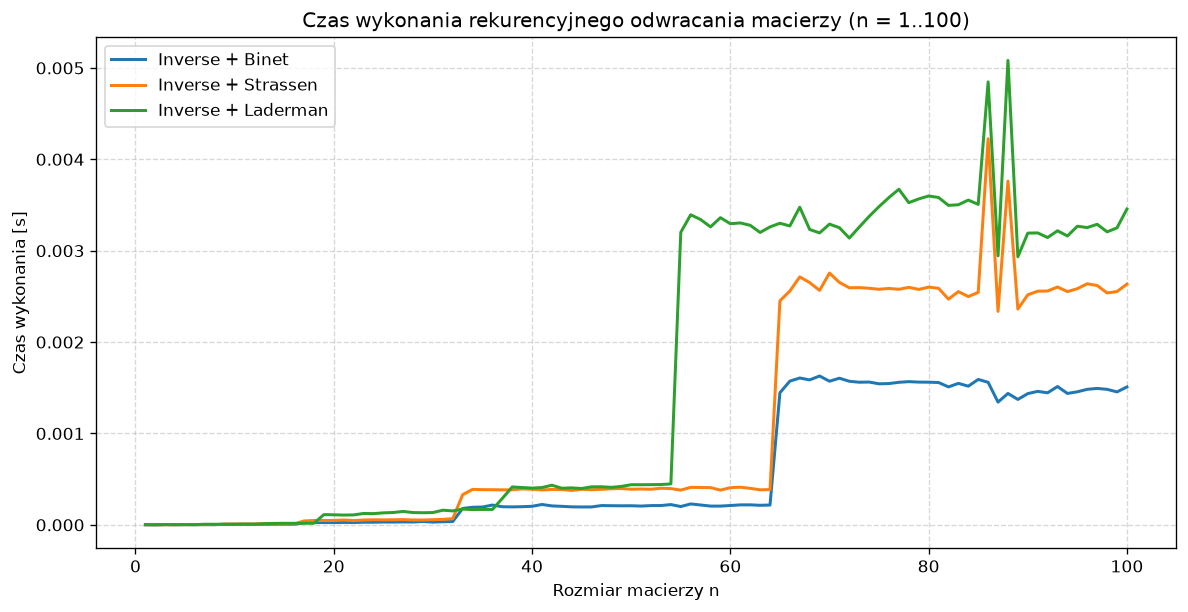

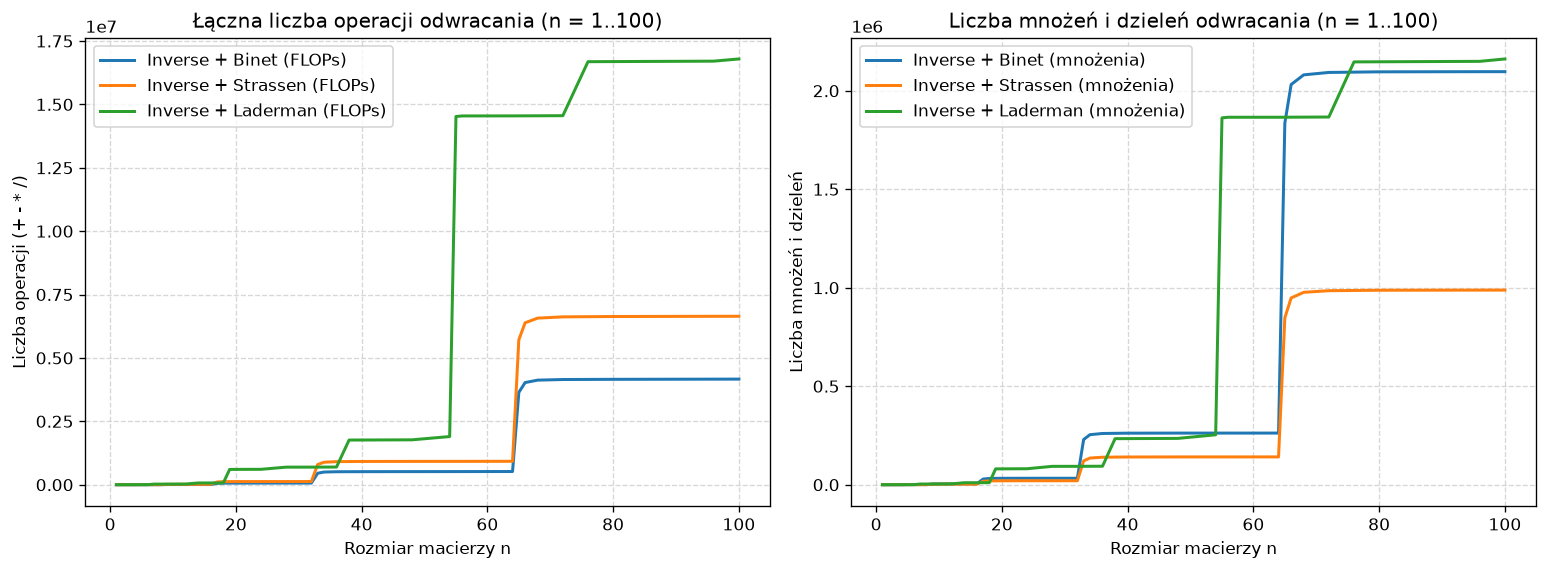

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sizes_100, results["inv_binet"]["time"][:100], label="Inverse + Binet", linewidth=1.8, color="#1f77b4")
ax.plot(sizes_100, results["inv_strassen"]["time"][:100], label="Inverse + Strassen", linewidth=1.8, color="#ff7f0e")
ax.plot(sizes_100, results["inv_laderman"]["time"][:100], label="Inverse + Laderman", linewidth=1.8, color="#2ca02c")
ax.set_title("Czas wykonania rekurencyjnego odwracania macierzy (n = 1..100)")
ax.set_xlabel("Rozmiar macierzy n")
ax.set_ylabel("Czas wykonania [s]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("typst/imgs/inverse_time_100.png", dpi=200)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
ax1.plot(sizes_100, results["inv_binet"]["flops"][:100], label="Inverse + Binet (FLOPs)", linewidth=1.8,
         color="#1f77b4")
ax1.plot(sizes_100, results["inv_strassen"]["flops"][:100], label="Inverse + Strassen (FLOPs)", linewidth=1.8,
         color="#ff7f0e")
ax1.plot(sizes_100, results["inv_laderman"]["flops"][:100], label="Inverse + Laderman (FLOPs)", linewidth=1.8,
         color="#2ca02c")
ax1.set_title("Łączna liczba operacji odwracania (n = 1..100)")
ax1.set_xlabel("Rozmiar macierzy n")
ax1.set_ylabel("Liczba operacji (+ - * /)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(sizes_100, results["inv_binet"]["m_ops"][:100], label="Inverse + Binet (mnożenia)", linewidth=1.8,
         color="#1f77b4")
ax2.plot(sizes_100, results["inv_strassen"]["m_ops"][:100], label="Inverse + Strassen (mnożenia)", linewidth=1.8,
         color="#ff7f0e")
ax2.plot(sizes_100, results["inv_laderman"]["m_ops"][:100], label="Inverse + Laderman (mnożenia)", linewidth=1.8,
         color="#2ca02c")
ax2.set_title("Liczba mnożeń i dzieleń odwracania (n = 1..100)")
ax2.set_xlabel("Rozmiar macierzy n")
ax2.set_ylabel("Liczba mnożeń i dzieleń")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("typst/imgs/inverse_flops_100.png", dpi=200)
plt.show()

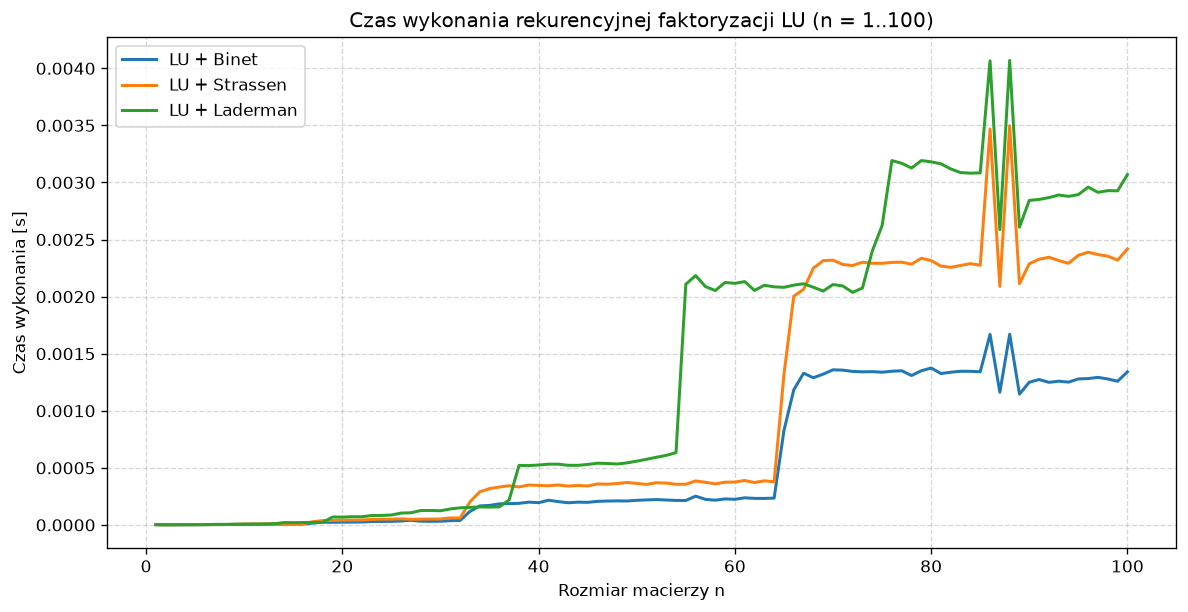

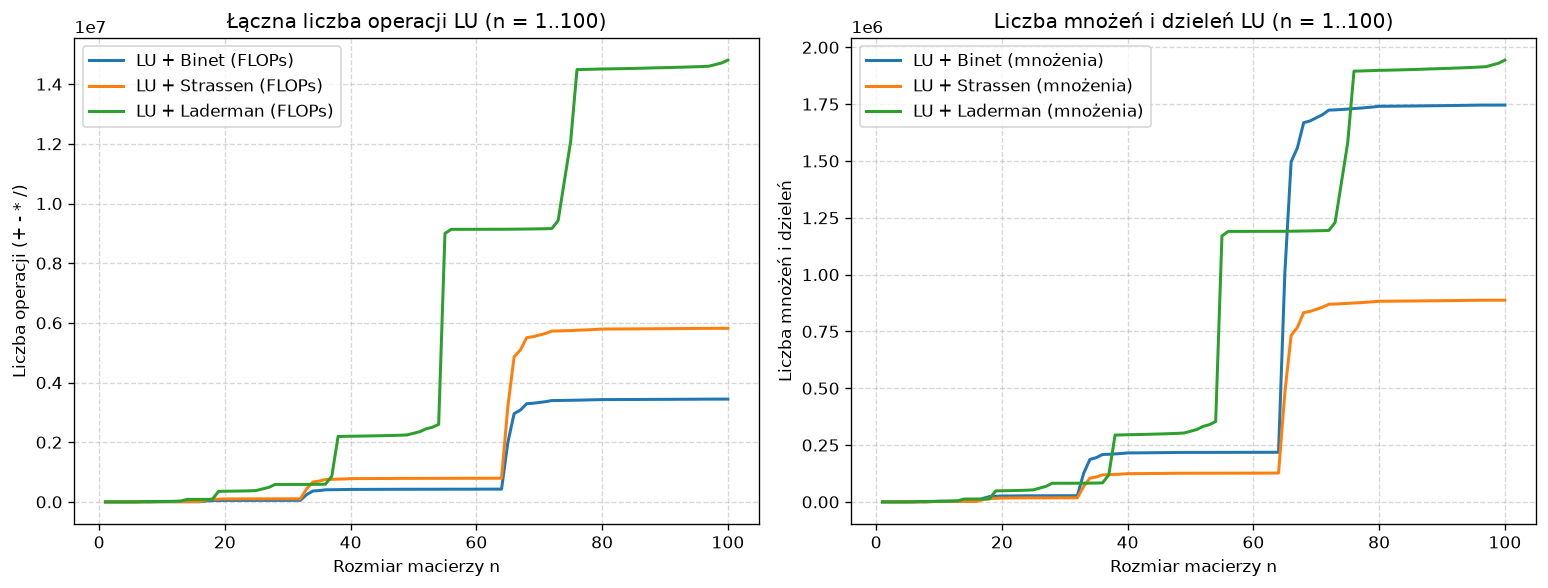

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sizes_100, results["lu_binet"]["time"][:100], label="LU + Binet", linewidth=1.8, color="#1f77b4")
ax.plot(sizes_100, results["lu_strassen"]["time"][:100], label="LU + Strassen", linewidth=1.8, color="#ff7f0e")
ax.plot(sizes_100, results["lu_laderman"]["time"][:100], label="LU + Laderman", linewidth=1.8, color="#2ca02c")
ax.set_title("Czas wykonania rekurencyjnej faktoryzacji LU (n = 1..100)")
ax.set_xlabel("Rozmiar macierzy n")
ax.set_ylabel("Czas wykonania [s]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("typst/imgs/lu_time_100.png", dpi=200)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
ax1.plot(sizes_100, results["lu_binet"]["flops"][:100], label="LU + Binet (FLOPs)", linewidth=1.8, color="#1f77b4")
ax1.plot(sizes_100, results["lu_strassen"]["flops"][:100], label="LU + Strassen (FLOPs)", linewidth=1.8,
         color="#ff7f0e")
ax1.plot(sizes_100, results["lu_laderman"]["flops"][:100], label="LU + Laderman (FLOPs)", linewidth=1.8,
         color="#2ca02c")
ax1.set_title("Łączna liczba operacji LU (n = 1..100)")
ax1.set_xlabel("Rozmiar macierzy n")
ax1.set_ylabel("Liczba operacji (+ - * /)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(sizes_100, results["lu_binet"]["m_ops"][:100], label="LU + Binet (mnożenia)", linewidth=1.8, color="#1f77b4")
ax2.plot(sizes_100, results["lu_strassen"]["m_ops"][:100], label="LU + Strassen (mnożenia)", linewidth=1.8,
         color="#ff7f0e")
ax2.plot(sizes_100, results["lu_laderman"]["m_ops"][:100], label="LU + Laderman (mnożenia)", linewidth=1.8,
         color="#2ca02c")
ax2.set_title("Liczba mnożeń i dzieleń LU (n = 1..100)")
ax2.set_xlabel("Rozmiar macierzy n")
ax2.set_ylabel("Liczba mnożeń i dzieleń")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("typst/imgs/lu_flops_100.png", dpi=200)
plt.show()

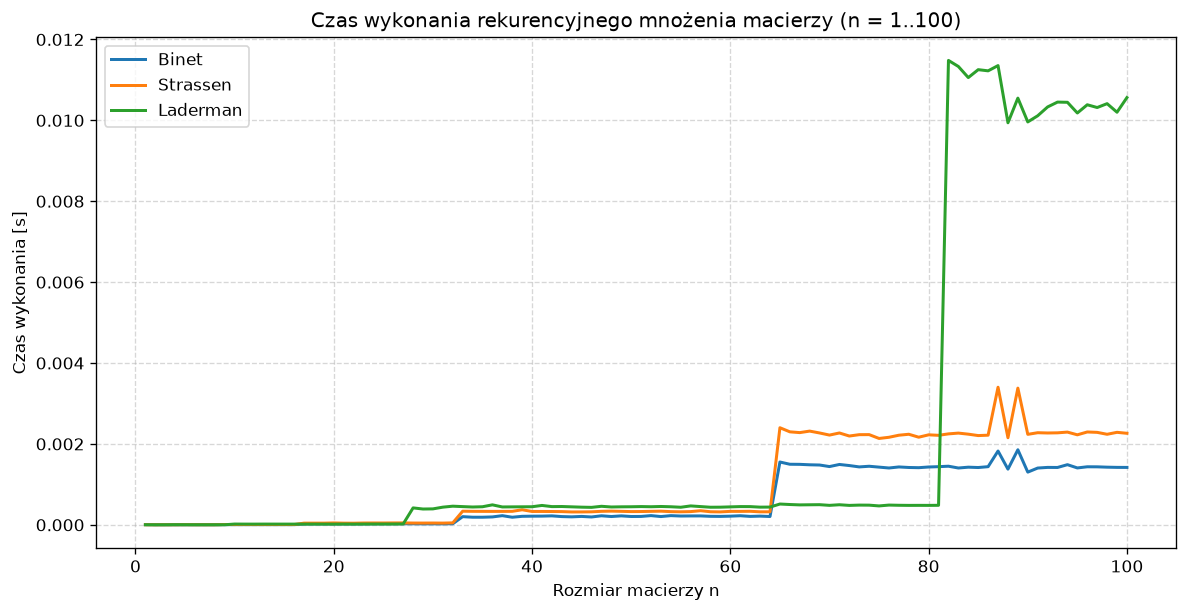

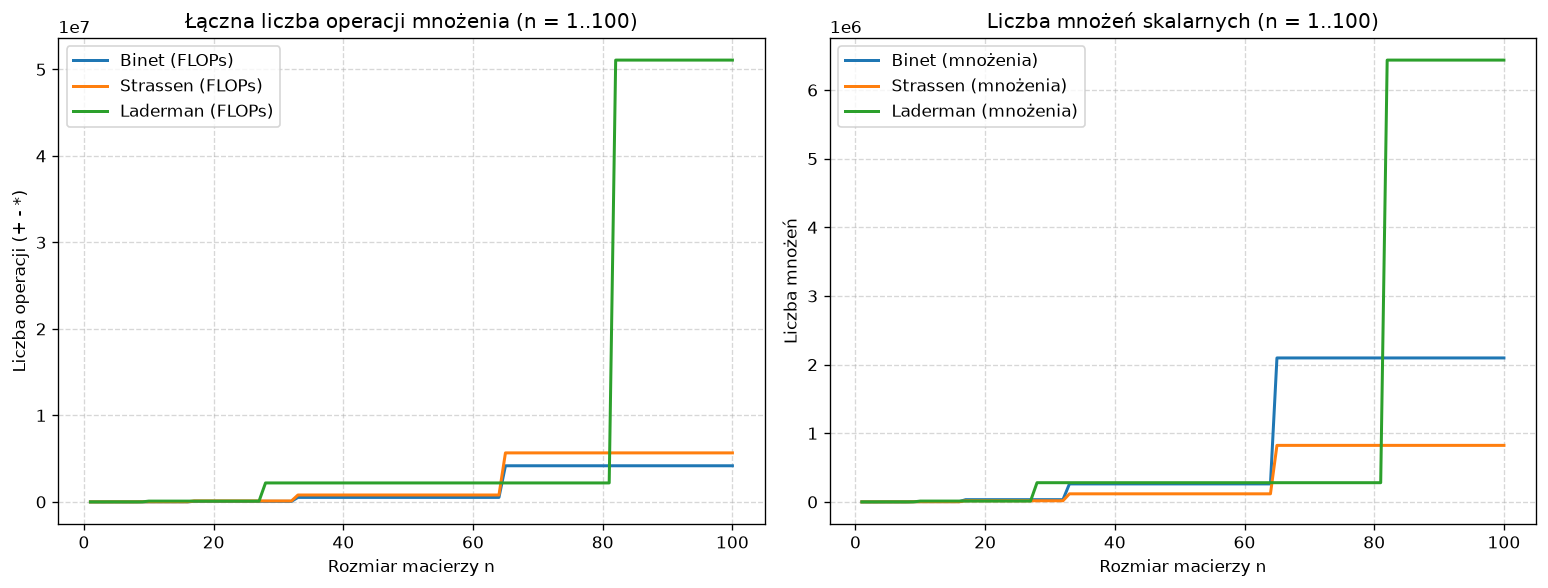

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sizes_100, results["mul_binet"]["time"][:100], label="Binet", linewidth=1.8, color="#1f77b4")
ax.plot(sizes_100, results["mul_strassen"]["time"][:100], label="Strassen", linewidth=1.8, color="#ff7f0e")
ax.plot(sizes_100, results["mul_laderman"]["time"][:100], label="Laderman", linewidth=1.8, color="#2ca02c")
ax.set_title("Czas wykonania rekurencyjnego mnożenia macierzy (n = 1..100)")
ax.set_xlabel("Rozmiar macierzy n")
ax.set_ylabel("Czas wykonania [s]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("typst/imgs/laderman_mul_time_100.png", dpi=200)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
ax1.plot(sizes_100, results["mul_binet"]["flops"][:100], label="Binet (FLOPs)", linewidth=1.8, color="#1f77b4")
ax1.plot(sizes_100, results["mul_strassen"]["flops"][:100], label="Strassen (FLOPs)", linewidth=1.8, color="#ff7f0e")
ax1.plot(sizes_100, results["mul_laderman"]["flops"][:100], label="Laderman (FLOPs)", linewidth=1.8, color="#2ca02c")
ax1.set_title("Łączna liczba operacji mnożenia (n = 1..100)")
ax1.set_xlabel("Rozmiar macierzy n")
ax1.set_ylabel("Liczba operacji (+ - *)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(sizes_100, results["mul_binet"]["m_ops"][:100], label="Binet (mnożenia)", linewidth=1.8, color="#1f77b4")
ax2.plot(sizes_100, results["mul_strassen"]["m_ops"][:100], label="Strassen (mnożenia)", linewidth=1.8, color="#ff7f0e")
ax2.plot(sizes_100, results["mul_laderman"]["m_ops"][:100], label="Laderman (mnożenia)", linewidth=1.8, color="#2ca02c")
ax2.set_title("Liczba mnożeń skalarnych (n = 1..100)")
ax2.set_xlabel("Rozmiar macierzy n")
ax2.set_ylabel("Liczba mnożeń")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("typst/imgs/laderman_mul_flops_100.png", dpi=200)
plt.show()

### Wykresy dla $n_{\max} = 1000$

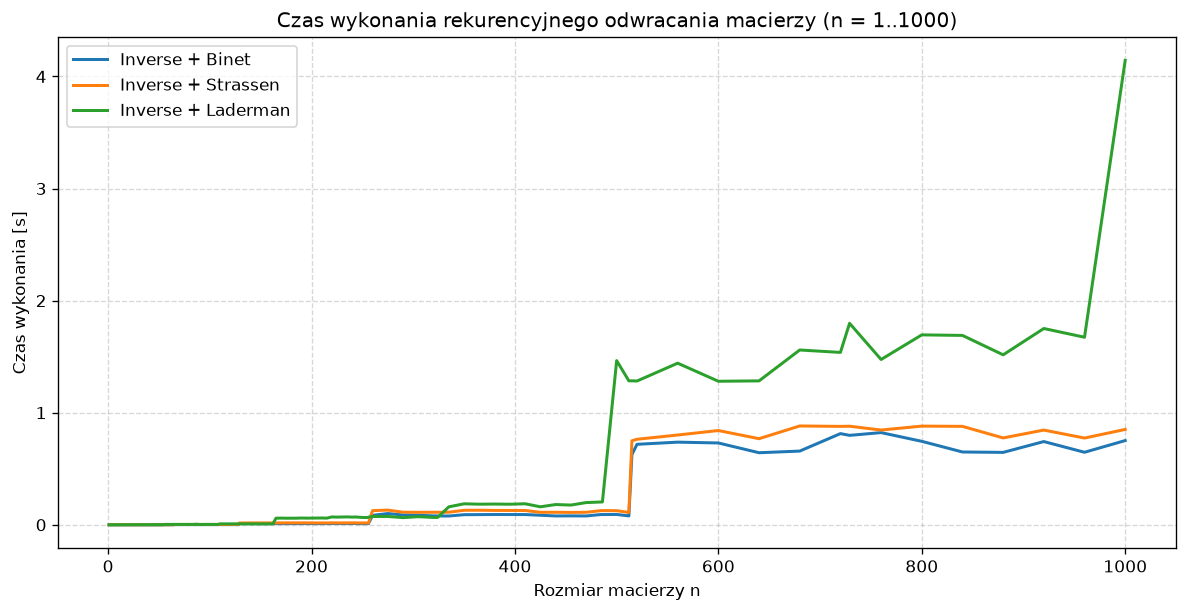

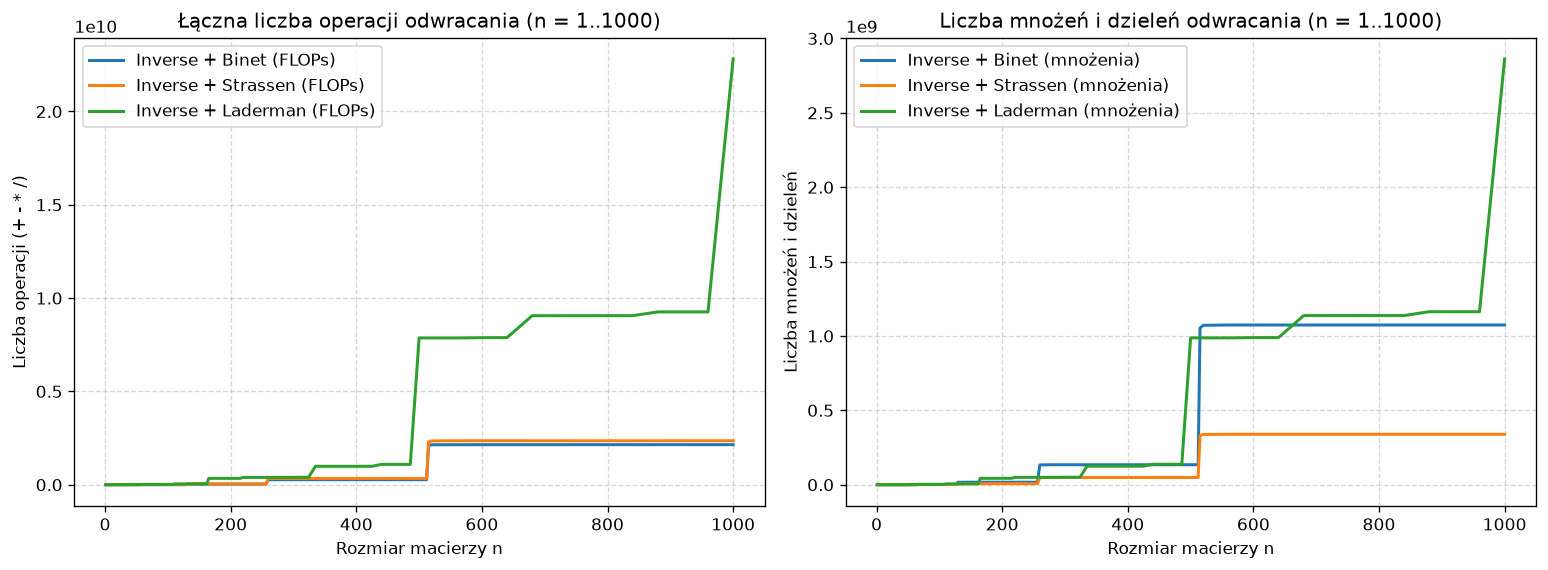

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sizes, results["inv_binet"]["time"], label="Inverse + Binet", linewidth=1.8, color="#1f77b4")
ax.plot(sizes, results["inv_strassen"]["time"], label="Inverse + Strassen", linewidth=1.8, color="#ff7f0e")
ax.plot(sizes, results["inv_laderman"]["time"], label="Inverse + Laderman", linewidth=1.8, color="#2ca02c")
ax.set_title("Czas wykonania rekurencyjnego odwracania macierzy (n = 1..1000)")
ax.set_xlabel("Rozmiar macierzy n")
ax.set_ylabel("Czas wykonania [s]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("typst/imgs/inverse_time.png", dpi=200)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
ax1.plot(sizes, results["inv_binet"]["flops"], label="Inverse + Binet (FLOPs)", linewidth=1.8, color="#1f77b4")
ax1.plot(sizes, results["inv_strassen"]["flops"], label="Inverse + Strassen (FLOPs)", linewidth=1.8, color="#ff7f0e")
ax1.plot(sizes, results["inv_laderman"]["flops"], label="Inverse + Laderman (FLOPs)", linewidth=1.8, color="#2ca02c")
ax1.set_title("Łączna liczba operacji odwracania (n = 1..1000)")
ax1.set_xlabel("Rozmiar macierzy n")
ax1.set_ylabel("Liczba operacji (+ - * /)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(sizes, results["inv_binet"]["m_ops"], label="Inverse + Binet (mnożenia)", linewidth=1.8, color="#1f77b4")
ax2.plot(sizes, results["inv_strassen"]["m_ops"], label="Inverse + Strassen (mnożenia)", linewidth=1.8, color="#ff7f0e")
ax2.plot(sizes, results["inv_laderman"]["m_ops"], label="Inverse + Laderman (mnożenia)", linewidth=1.8, color="#2ca02c")
ax2.set_title("Liczba mnożeń i dzieleń odwracania (n = 1..1000)")
ax2.set_xlabel("Rozmiar macierzy n")
ax2.set_ylabel("Liczba mnożeń i dzieleń")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("typst/imgs/inverse_flops.png", dpi=200)
plt.show()

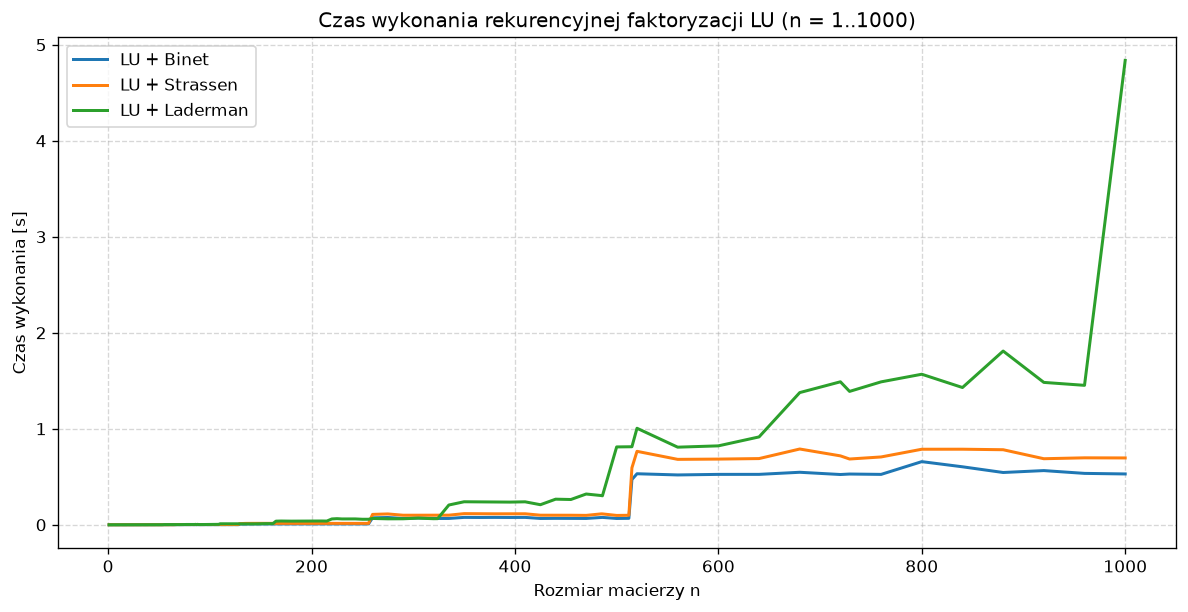

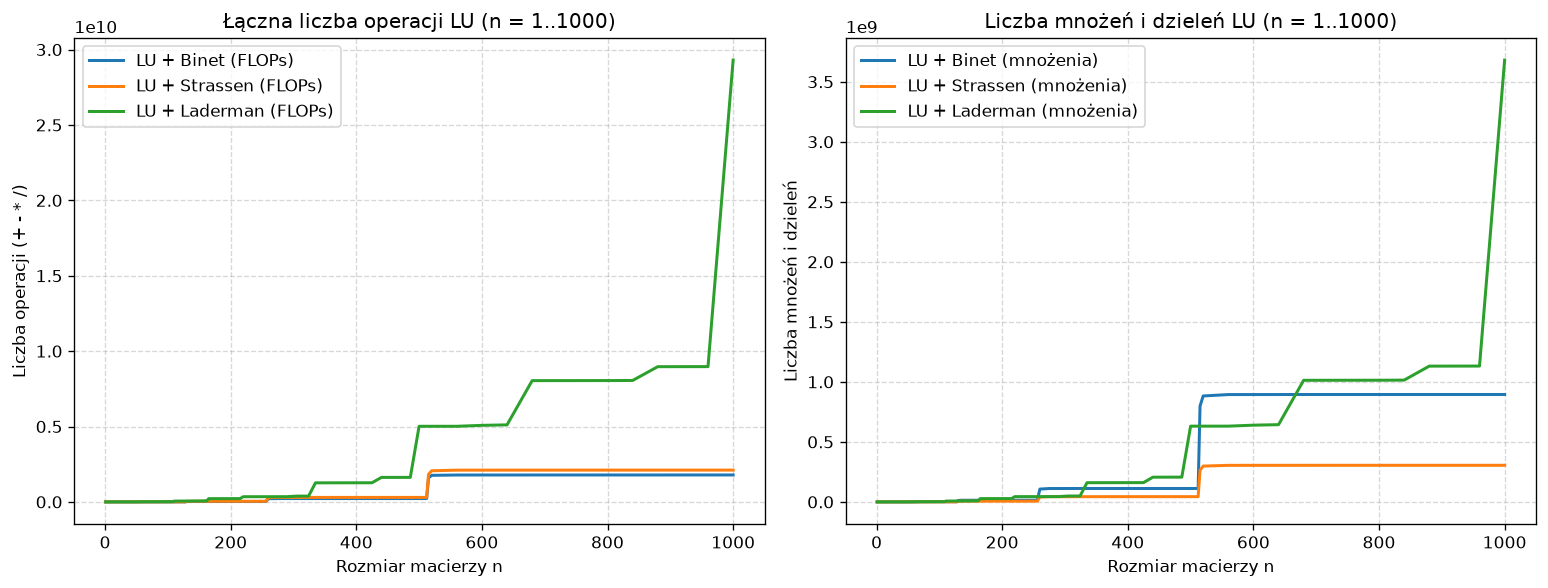

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sizes, results["lu_binet"]["time"], label="LU + Binet", linewidth=1.8, color="#1f77b4")
ax.plot(sizes, results["lu_strassen"]["time"], label="LU + Strassen", linewidth=1.8, color="#ff7f0e")
ax.plot(sizes, results["lu_laderman"]["time"], label="LU + Laderman", linewidth=1.8, color="#2ca02c")
ax.set_title("Czas wykonania rekurencyjnej faktoryzacji LU (n = 1..1000)")
ax.set_xlabel("Rozmiar macierzy n")
ax.set_ylabel("Czas wykonania [s]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("typst/imgs/lu_time.png", dpi=200)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
ax1.plot(sizes, results["lu_binet"]["flops"], label="LU + Binet (FLOPs)", linewidth=1.8, color="#1f77b4")
ax1.plot(sizes, results["lu_strassen"]["flops"], label="LU + Strassen (FLOPs)", linewidth=1.8, color="#ff7f0e")
ax1.plot(sizes, results["lu_laderman"]["flops"], label="LU + Laderman (FLOPs)", linewidth=1.8, color="#2ca02c")
ax1.set_title("Łączna liczba operacji LU (n = 1..1000)")
ax1.set_xlabel("Rozmiar macierzy n")
ax1.set_ylabel("Liczba operacji (+ - * /)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(sizes, results["lu_binet"]["m_ops"], label="LU + Binet (mnożenia)", linewidth=1.8, color="#1f77b4")
ax2.plot(sizes, results["lu_strassen"]["m_ops"], label="LU + Strassen (mnożenia)", linewidth=1.8, color="#ff7f0e")
ax2.plot(sizes, results["lu_laderman"]["m_ops"], label="LU + Laderman (mnożenia)", linewidth=1.8, color="#2ca02c")
ax2.set_title("Liczba mnożeń i dzieleń LU (n = 1..1000)")
ax2.set_xlabel("Rozmiar macierzy n")
ax2.set_ylabel("Liczba mnożeń i dzieleń")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("typst/imgs/lu_flops.png", dpi=200)
plt.show()

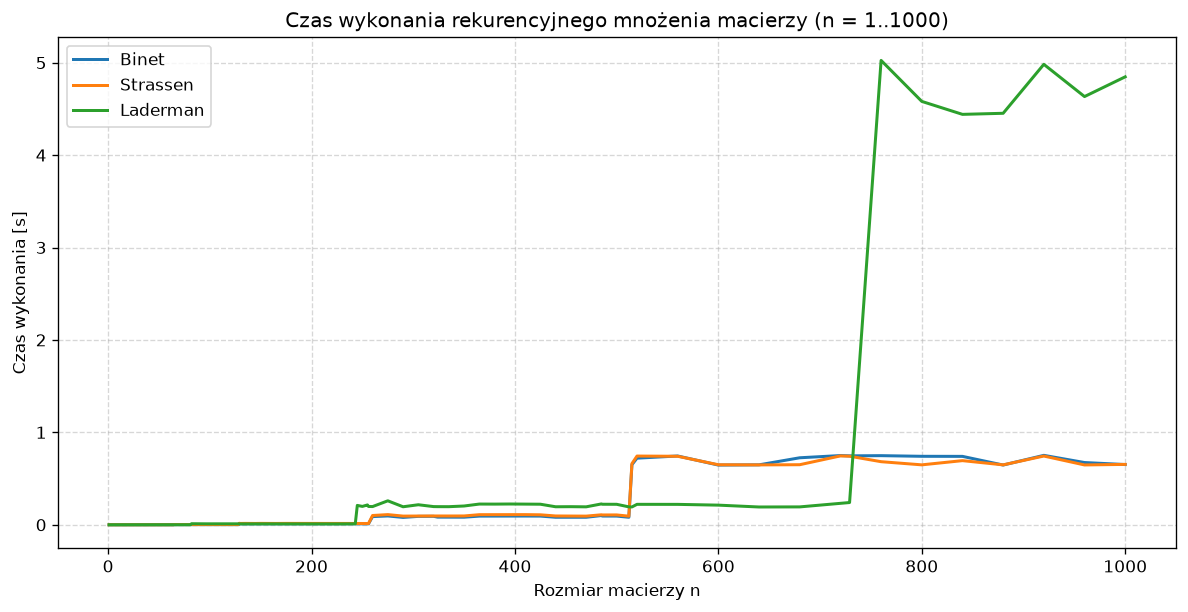

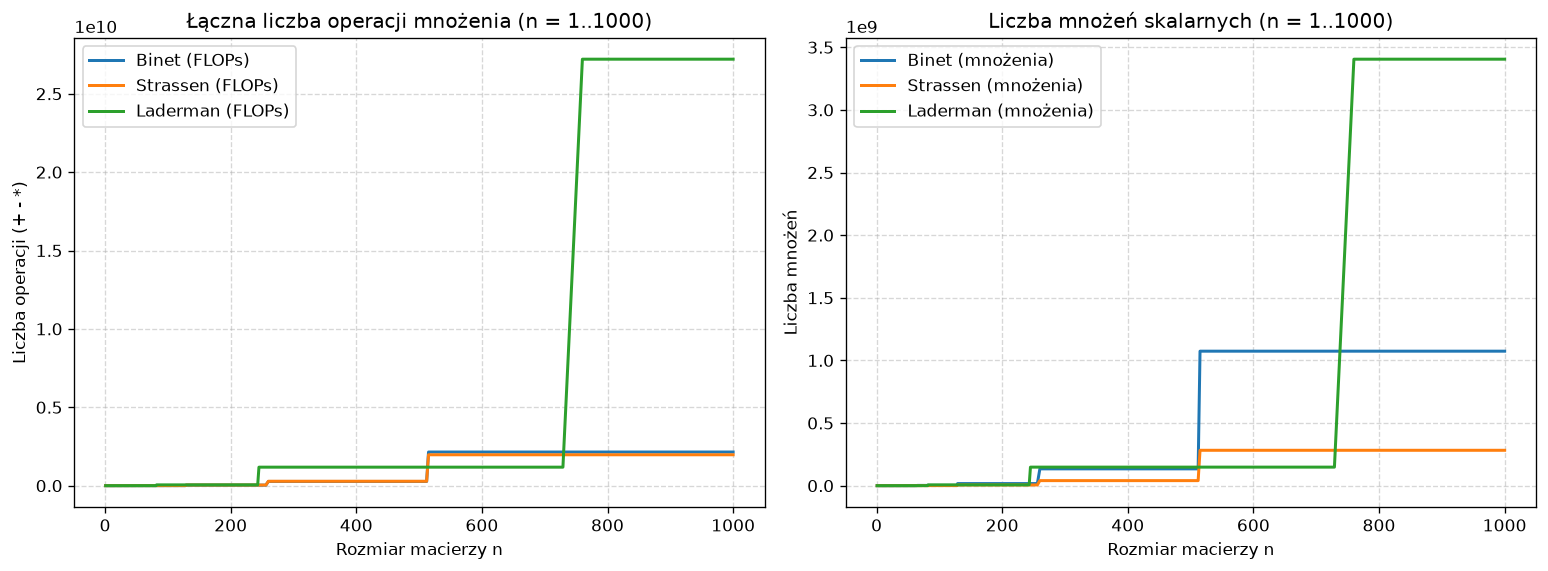

In [13]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sizes, results["mul_binet"]["time"], label="Binet", linewidth=1.8, color="#1f77b4")
ax.plot(sizes, results["mul_strassen"]["time"], label="Strassen", linewidth=1.8, color="#ff7f0e")
ax.plot(sizes, results["mul_laderman"]["time"], label="Laderman", linewidth=1.8, color="#2ca02c")
ax.set_title("Czas wykonania rekurencyjnego mnożenia macierzy (n = 1..1000)")
ax.set_xlabel("Rozmiar macierzy n")
ax.set_ylabel("Czas wykonania [s]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("typst/imgs/laderman_mul_time.png", dpi=200)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
ax1.plot(sizes, results["mul_binet"]["flops"], label="Binet (FLOPs)", linewidth=1.8, color="#1f77b4")
ax1.plot(sizes, results["mul_strassen"]["flops"], label="Strassen (FLOPs)", linewidth=1.8, color="#ff7f0e")
ax1.plot(sizes, results["mul_laderman"]["flops"], label="Laderman (FLOPs)", linewidth=1.8, color="#2ca02c")
ax1.set_title("Łączna liczba operacji mnożenia (n = 1..1000)")
ax1.set_xlabel("Rozmiar macierzy n")
ax1.set_ylabel("Liczba operacji (+ - *)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(sizes, results["mul_binet"]["m_ops"], label="Binet (mnożenia)", linewidth=1.8, color="#1f77b4")
ax2.plot(sizes, results["mul_strassen"]["m_ops"], label="Strassen (mnożenia)", linewidth=1.8, color="#ff7f0e")
ax2.plot(sizes, results["mul_laderman"]["m_ops"], label="Laderman (mnożenia)", linewidth=1.8, color="#2ca02c")
ax2.set_title("Liczba mnożeń skalarnych (n = 1..1000)")
ax2.set_xlabel("Rozmiar macierzy n")
ax2.set_ylabel("Liczba mnożeń")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("typst/imgs/laderman_mul_flops.png", dpi=200)
plt.show()

In [14]:
fit_mask = np.array(sizes) >= 16
log_n = np.log(np.array(sizes)[fit_mask])
idx_100 = sizes.index(100)
idx_1000 = sizes.index(1000)

print(
    f"{'Algorytm':<19} | {'Wykł. FLOPs':>12} | {'Wykł. Mnożeń':>13} | {'Wykł. Czasu':>12} | {'Czas n=100 [ms]':>15} | {'Czas n=1000 [s]':>15} | {'Mnożenia n=1000':>16} | {'FLOPs n=1000':>16}")
print("-" * 138)
for key, label in [
    ("mul_binet", "Mnożenie Binet"),
    ("mul_strassen", "Mnożenie Strassen"),
    ("mul_laderman", "Mnożenie Laderman"),
    ("inv_binet", "Odwracanie Binet"),
    ("inv_strassen", "Odwracanie Strassen"),
    ("inv_laderman", "Odwracanie Laderman"),
    ("lu_binet", "LU Binet"),
    ("lu_strassen", "LU Strassen"),
    ("lu_laderman", "LU Laderman"),
]:
    exp_flops = np.polyfit(log_n, np.log(np.array(results[key]["flops"], dtype=float)[fit_mask]), 1)[0]
    exp_mops = np.polyfit(log_n, np.log(np.array(results[key]["m_ops"], dtype=float)[fit_mask]), 1)[0]
    exp_time = np.polyfit(log_n, np.log(np.maximum(np.array(results[key]["time"], dtype=float)[fit_mask], 1e-7)), 1)[0]
    t100 = results[key]["time"][idx_100] * 1000
    t1000 = results[key]["time"][idx_1000]
    m1000 = results[key]["m_ops"][idx_1000]
    f1000 = results[key]["flops"][idx_1000]
    print(
        f"{label:<19} | {exp_flops:12.3f} | {exp_mops:13.3f} | {exp_time:12.3f} | {t100:15.2f} | {t1000:15.3f} | {m1000:16d} | {f1000:16d}")

Algorytm            |  Wykł. FLOPs |  Wykł. Mnożeń |  Wykł. Czasu | Czas n=100 [ms] | Czas n=1000 [s] |  Mnożenia n=1000 |     FLOPs n=1000
------------------------------------------------------------------------------------------------------------------------------------------
Mnożenie Binet      |        2.914 |         2.910 |        2.849 |            1.42 |           0.652 |       1073741824 |       2146435072
Mnożenie Strassen   |        2.736 |         2.723 |        2.681 |            2.26 |           0.653 |        282475249 |       1971035287
Mnożenie Laderman   |        2.907 |         2.897 |        2.848 |           10.56 |           4.847 |       3404825447 |      27205122793
Odwracanie Binet    |        2.921 |         2.914 |        2.811 |            1.51 |           0.751 |       1073741656 |       2146337912
Odwracanie Strassen |        2.759 |         2.728 |        2.684 |            2.63 |           0.851 |        338969926 |       2355926522
Odwracanie Laderman |